<a href="https://colab.research.google.com/github/alexey1978malyshev/4236_team/blob/main/%D0%9A%D0%B5%D0%B9%D1%81_%E2%84%96_3_DeepWalk_%2B_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Описание кейса


<p>Данная работа посвящена отработке навыков использования методов получения векторного представления узлов графа (эмбеддинг) на примере метода Deepwalk. В качестве входных данных предлагается датасет, построенный по данным из социальной сети.</p>
<p>   Социальный граф, представляет участников локального спортивного сибирского сообщества, проживающих в сибирских городах Томск, Новосибирск, Кемерово, Новокузнецк, Красноярск и некоторых других. Всех этих людей объединяет участие в офлайн мероприятиях по теме сообщества, проходящих в Cибири. В социальных сетях эти люди имеют профили и состоят в двух крупных группах по интересу. Организаторы одной группы проживают в г. Томск, вторая группа относится к г. Новосибирск. </p>
<p>
Разметка сделана по географическому местоположению.
Метка 1 - Участник из г. Томск
Метка 2 - участник из Г. Новосибирск
Метка 3 - участник с закрытым профилем без указания города, либо указан другой город (т.е. не томск и не новосибирск) и участник состоит в томской группе
Метка 4 - участник с закрытым профилем без указания города, либо указан другой город (т.е. не томск и не новосибирск) и участник состоит в новаосибирской группе.
</p>
Метки 3 и 4 - показывает демонстрирует наличие в данных фоновых объекты. Такие объекты могут быть шумовыми.
<p>
Ребра в социальном графе были построены по принципу дружбы между участниками сообществ. Связи (ребра) для закрытых профилей были восстановлены, если имелись друзья с открытыми профилями. </p>



# Задание

Задание.
<ol>
<li>
Визуализировать граф в спец. пакете gephi/cytoscape. Вычислите модулярность и расскрасьте узлы графа по модулярности. Сколько групп в рамках предложенного социального графа можно выделить судя по модулярности?
</li>
<li>Заполнить отсутствующие строки кода по заданию. Через содержание эти элементы обозначены "Вставить код" Последний элемент п.10 (см. содержание в ноутбуке) потребует и вставку кода, анализ промежуточных результатов, выбор лучших параметров и последующую их подстановку в код.</li>
<li> Отправьте ноутбук в качестве ответа на задание</li>
<li> Выполните тест в электронном курсе, который в том числе, будет содержать вопросы, связанные с данным ноутбуком. Эти вопросы перечислены ниже</li>
<li>Какое количество узлов, осталось после обработки графа методом луковой шелухи со степенью 2?
</li>
<li>После применения метода DeepWalk укажите длину вектора, т.е. какое значение dimention оказалось у каждого вектора? </li>
</ol>



# Используемые библиотеки

In [3]:
# ВЫПОЛНИТЬ УСТАНОВКУ БИБЛИОТЕКИ  gensim И ПЕРЕЗАПУСТИТЬ СЕАНС: главное меню-->Среда выполнения->Перезапустить сеанс.

!pip install gensim
#ПОСЛЕ ПЕРЕЗАПУСКА СЕАНСА повторно эту строку выполнять не нужно

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 26.0 MB/s  0:00:01


In [4]:
#используемые библиотеки
import networkx as nx # работа с графом

import pandas as pd

from tqdm import tqdm #отслеживание прогресса выполнения

import numpy as np

import random
from random import randint

from gensim.models import Word2Vec #word2vec
import warnings

#снижение размерности для визуализации
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns


from sklearn import metrics # метрики качества кластерного анализа

# Шаг 1. Обработка исходных данных

Шаг 1. Исходные данные представлены в формате *.graphml. Считайте эти данные и преобразуйте в граф используя библиотеку networkx. Если работа выполняется в гугл колаб, то есть три способа загрузить файл:
<ol>
<li>
через гугл колаб файл загружается и размещается во временной директории весь сеанс работы (при повторном запуске ноутбука, нужно отказаться от повторной загруки).</li>
<li>
Самостоятельно загрузить файл во временную директорию (см. панель слева и рисунок ниже)</li>
<li>Загрузить на гугл диск и работать с ним.</li>
<b>Ниже на рисунке показано как загрузить файл во временное хранилище.</b></ol>

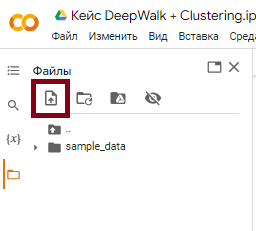

# **1. ВСТАВИТЬ КОД**
Ниже вставьте 1 строку кода, которая позволяет считать данные в формате graphml и преобразует эти данные в стуктуру граф библиотеки networkx.
Используйте функцию  [read_graphml](https://networkx.org/documentation/stable/reference/readwrite/generated/networkx.readwrite.graphml.read_graphml.html)
Ознакомьтесь пожалуйта со ссылкой на документацию. Используйте единственный параметр path - укажите имя файла и расширение следующим образом "file_name.graphml".


In [5]:
G=None
# 1. ВСТАВИТЬ КОД
# вставьте программный код сюда, прочитав исходнные данные в переменную G
G = nx.read_graphml("sample_data/graph_dataset.graphml")


# Шаг 2. Предварительная обработка графа.
Обрабатываемый граф может содержать некоторое количество шума или не значимых узлов. К таким узлам, в частности, относятся изолированные узлы.

Если говорить о социальном графе, то в сообщества (т.е. в открытые группы) в социальной сети могут присоединяться случайные пользователи, например, те, которые по какой-то прчине имели кратковременный интерес к теме сообществаб но больше не имеют этот интерес, малоактивные участники. Узлы, соответствующие таким пользователям в социальном графе будут иметь низкую степень или могут быть изолированными. Такие узлы могут зашумлять соцальный граф.

Для того, чтобы оценить структуру графа, и обрабатывать более значимые, с точки зрения структуры графа, узлы, более эффективно обнаруживать внутри графа сообщества, повысить эффективность решения конечной задачи, например, классификацию, а также обнаружить эти незначимые узлы, используется прием удаление узлов из графа методом луковой шелухи.
Нужно отметить, что в первую очередь этот метод используется для оценки устойчивости сети и выявления ключевых компонентов в структуре графа.

Ссылки по теме:
1. Лекция от 2018 г. от Юре Лесковца, курс CS 224W назывался на момент 2018 г."Анализ социальных сетей" [ссылка](https://snap.stanford.edu/class/cs224w-videos-2018/181108-cs224w-720.mp4) 36 минута - 30 минута
в лекции данный метод используется в применительно к оценки устойчивости сетевой структуры.
2. Статья Multi-scale structure and topological anomaly detection via a new network statistic: The onion decomposition от 2016 г. [ссылка](https://www.researchgate.net/publication/306309687_Multi-scale_structure_and_topological_anomaly_detection_via_a_new_network_statistic_The_onion_decomposition)


Идея метода состоит в том, чтобы задаться некоторой степенью k. И далее удалять из графа узлы до тех пор, пока не останутся узлы со степенью не ниже чем k+1.

Например, если задаться степенью k=1. То из графа должны быть удалены все изолированные узлы и все висячие вершины. Если после удаления останутся снова изолированные узлы и висячие вершины (т.е. их степень = 1), то процесс повторяется до тех пор, пока не останутся вершины со степенью 2. Процесс похож на снятие луковой шелухи. В ходе очистки можно оценивать долю узлов, находящихся на каждой итерации очистки.



#**2. ВСТАВИТЬ КОД**


Реализуйте до конца предложенный алгоритм, который позволяет удалять узлы со степенью меньше или равной заданной dk.
Алгоритм работает по флагу. Пока флаг не равен 1, в графе все еще могут быть узлы со степенью меньше или равной заданной. Если такие узлы находятся., то их нужно удалить и обнулить флаг, потому что при удалении узла, степень некоторых узлов может снизится и эти узлы также будут подлежать удалению в следующем проходе. Реализуйте данное условие и удаление узла.

Степень узла можно проверить при помощи индексированного оператора degree[i], [ссылка на документацию](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.degree.html)
Удаление узла, можно выполнить посредством использования метода remove_node(i) [ссылка на документацию ](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.remove_node.html)


In [17]:
# G - граф, структура networkx
# dk - узлы степень меньше или равной которой следует удалить.
def onion_peel_1(G, dk):
  G1 = G.copy()
  f=0
  while f!=1:
    f=1
    for v in list(G1.nodes()):
      # 2. ВСТАВИТЬ КОД #############
      # вставьте код тут ~3 строки
      # Если степень узла v меньше или равна заданной, то данный узел следует удалить и обнулить флаг f.
      if G1.degree[v] <= dk:
         G1.remove_node(v)
         f = 0
      ##########################################
  return G1

Оцените, сколько узлов было удалено при dk = 2. Используйте свойство nodes или метод nodes() [ссылка на документацию](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.nodes.html) для объекта граф. Свойство и метод позволяют получить список узлов. Далее оцените длину списка при помощи функции len и таким образом оцените общее число узлов, которое было до применения функции onion_peel и осталось после.


In [18]:

nodes_number_before = len(G.nodes ) # оценим сколько было узлов до удаления
G1 = onion_peel_1(G,2) # применим реализованную функцию
# расчитайте сколько узлов осталось  ~ 1 строка кода
number_del = len(G1.nodes )
print(number_del)






2274


# DeepWalk формирование векторного представления узлов графа


Для того, чтобы поставить в соответствие каждому узлу графа вектор, необходимо выполнить 2 глобальных шага в рамках метода DeepWalk:
1. Сформировать цепочки случаных блужданий по графу
2. Применить модель SkipGram, которая позволяет сформировать для каждого узла такие вектора, чтобы по центральному узлу максимально эффективно угадвать контекстные узлы в цепочках случайных блужданий.

Определим функцию выполняющую случайные блуждания по графу G. В качестве параметров передается
 , идентификатор стартового узла, и длина списка случайных блужданий, т.е.

*   G - граф
*   node - идентификатор стартового узла
*   t- число шагов в каждом блуждании.

На выходе функции - массив, состоящий из цепочек (массивов) случайных блужданий.

# **4. ВСТАВИТЬ КОД**

Доработайте реализацию данной функции.
Для заданного узла node, необходимо получить список его соседей (т.е. смежные узлы). Используйте функцию neighbors [ссылка на документацию](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.neighbors.html)

После этого уже вставлен программный код, который делает шаг в случайный узел из списка соседей и добавляет этот случайный узел к цепочке случайных блужданий


In [ ]:
# t - максимальная длина цепочки, построенной в ходе случайных блужданий
def get_randomwalk(G, node, t):

    random_walk = [node]
    #print ('начинаем с узла', random_walk)
    for i in range(t-1):
        temp = None
        # 4 ВСТАВИТЬ КОД
        # вставить программный код тут ~ 1 строка кода, в переменную temp получите соседей узла node при помощи функции neigbors
        #temp=

        # print('соседи', temp)
        if len(temp) == 0:
            break

        random_node = random.choice(temp)  # случайно сделаем шаг в следующий узел
        random_walk.append(random_node)
        node = random_node

    return random_walk

Далее реализуем заданное число случайных блужданий на каждый узел графа. Это число задано в переменной **gamma**. Используйте tqdm для того, чтобы отслеживать прогресс выполнения цикла.

In [ ]:
#необходимые библиотеки обозначены в комментариях
#from tqdm import tqdm
#import random

all_nodes = list(G1.nodes())
gamma = 80 # число случайных блужданий приходящихся на 1 узел. т.е. для каждого узла стартуем gamma раз
t = 80 # максимальная длина цепочки
random_walks = []
for n in tqdm(all_nodes):
    for i in range(gamma):
        random_walks.append(get_randomwalk(G1, n, t))

# полученное число случайных блужданий
len(random_walks)

100%|██████████| 2274/2274 [03:56<00:00,  9.61it/s]


181920

Далее выполним тренировку модели Skipgram по сформированным цепочкам случайных блужданий. Будем использовать метод word2vec уже реализованный алгоритм в библиотеке gensim.

  Параметры функции:

  window - размер окна

  sg = 1 - это значит будет использована модель skipgrapm


  hs {0, 1}, необязательный параметр) – Если 1,  будет использован иерархический софтмакс, если 0 - отрицательное сэмплирование.

  alpha - начальное значение - градиентный шаг;

  min_alpha  - условие остановки алгоритма;


  workers -  число потоков при вычислении


  seed - рэндом сид. Используйте значение 14 при выполнении работы.

 Нужно отметить, что возможна некоторая незначимая вариация получаемых значений в векторах даже при одном и том же random seed. Официальная документация поясняет это[ по ссылке](https://github.com/RaRe-Technologies/gensim/wiki/Recipes-&-FAQ#q11-ive-trained-my-word2vec--doc2vec--etc-model-repeatedly-using-the-exact-same-text-corpus-but-the-vectors-are-different-each-time-is-there-a-bug-or-have-i-made-a-mistake-2vec-training-non-determinism).  Дискусия [по ссылке](https://stackoverflow.com/questions/34831551/ensure-the-gensim-generate-the-same-word2vec-model-for-different-runs-on-the-sam) можно почитать как получить точно идентичные векторные представления из раза в раз обучения модели на тех же самых данных.
 Кроме этого, нужно отметить, что для этого и цепочки случаных блужданий нужно также фиксировать и формировать одинаковыми каждый раз.

Будем обрабатывать событие "окончание эпохи", и при наступлении этого события будем выводить ошибку обучения после каждой эпохи.

In [ ]:
from gensim.models.callbacks import CallbackAny2Vec
loss_list = []

class callback(CallbackAny2Vec):
    '''Callback to print loss after each epoch.'''

    def __init__(self):
        self.epoch = 0
        self.previous_loss = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        loss_now = loss - self.previous_loss
        self.previous_loss = loss
        print('Loss after epoch {}: {}'.format(self.epoch, loss_now))
        self.epoch += 1

Запустим процесс обучения модели

In [ ]:
model = Word2Vec(window = 5, sg = 1, hs = 1, batch_words=3000,
                 negative = 0, # for negative sampling
                 alpha=0.03, min_alpha=0.0001,
                 seed = 14, workers=4 ,vector_size=300, compute_loss=True)

model.build_vocab(random_walks, progress_per=2)
model.train(random_walks, total_examples = model.corpus_count, epochs=2, report_delay=1, callbacks=[callback()])

Для того, чтобы повторно не обучать модель, ее можно сохранить и загрузить снова. Ниже приведен пример программного кода.

Нужно отметить, что сохранена модель будет во временное хранилище, для последующего использования ее можно сохранить локально или в облачное хранилище.

In [ ]:
model.save("skipgram_2k.model")

#model = Word2Vec.load("skipgram_2k.model")

#  Работа с обученой моделью word2vec skipgram

Каждый узел графа в рамках библиотеке gensim получает индекс. Ниже можно посмотреть на эти индексы. Слева исходные идентификаторы узлов или далее ключи, справа индексы этих узлов.

In [ ]:
model.wv.key_to_index # первое значение это исходный номер узла, второе это индекс узла.

Ниже показано, как получить список узлов т.е. ключей из самой модели.

In [ ]:
# получем список узлов, из самой модели
keys = model.wv.key_to_index.keys()
keys

In [ ]:
model.wv.vectors # тут содержаться все векторные представления. Векторные представления идут по порядку ключей keys

In [ ]:
model.wv.vectors.shape # размер матрицы векторных представлений

# Поиск похожих объектов

Поиск схожих объектов на заданный может быть очень полезен. Применительно к заданному датасету эти данные можно использовать для распространения спортивных товаров и услуг, спортивное питание и т.п.


# **5. ВСТАВИТЬ КОД**

Посмотрим узлы, схожие с заданным.
Сначала найдитем метку класса некоторого заданного узла 2652 (Ключ это строка, а не число). Используйте обращение к атрибуту 'class' по принципу **G.nodes['узел']['атрибут']** Также к атрибуту можно обратиться при помощи функции get_node_attributes(G, name) [ссылка на документацию ](https://networkx.org/documentation/stable/reference/generated/networkx.classes.function.get_node_attributes.html)


 ~ 1 строка кода.


In [ ]:
# 5. ВСТАВИТЬ КОД
# ~1 строка кода выведете класс узла 2652


# **6. ВСТАВИТЬ КОД**

**Найдите 5 узлов похожих на заданный узел с ключом 2652. и выведите классы найденных схожих узлов**
Задачу можно решить при помощи:

**1.** функции most_similar (model.wv.most_similar) [ссылка на документацию](https://tedboy.github.io/nlps/generated/generated/gensim.models.Word2Vec.most_similar.html). Ножно отметить, что данная функция хороша тем, что она может находить наиболее похожие на группу заданных узлов. Эти узлы задаются в параметре positive = [узел1, узел2, ...]


**2.** функция similar_by_word (model.wv.similar_by_word) [ссылка на документацию](https://tedboy.github.io/nlps/generated/generated/gensim.models.Doc2Vec.similar_by_word.html?highlight=similar_by_word#gensim.models.Doc2Vec.similar_by_word) находит указанное количество наиболее похожих слов (узлов) и возвращает как их ключи, так и меру сходства - косинусную близость.



In [ ]:
# 6. ВСТАВИТЬ КОД
# Найдите 5 узлов похожих на заданный узел с ключом 2652 и выведите классы найденных схожих узлов ~ 3 строки кода



# **7. ВСТАВИТЬ КОД**

Найдите меру сходства двух узлов 2159 и 3043, использовав функцию similarity. (model.wv.similarity) [ссылка на документацию](https://tedboy.github.io/nlps/generated/generated/gensim.models.Word2Vec.similarity.html?highlight=similarity#gensim.models.Word2Vec.similarity)

In [ ]:
# 7. ВСТАВИТЬ КОД
# Найдите меру сходства двух узлов '2159' и '3043', использовав функцию similarity ~ 1 строка кода


Согласно порядку ключей сформируем матрицу векторных представлений и правильных ответов. Данный метод понадобится, если по ходу работы необходимо будет формировать матрицу векторных представлений только заданных узлов. Метод .[__getitem__  ](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.__getitem__)позволяет по ключу получать вектор.

In [ ]:
X_emb = []
y = []
for i in keys:
  X_emb.append(   model.wv.__getitem__(i)  )
  y.append(G.nodes[i]['class'])



In [ ]:
# сформируем датафрейм номер узла и класс
d = {'id_node':keys,'y':y}
df = pd.DataFrame(d)
df

In [ ]:
df.y.hist() # распределение по классам

# Применение векторных представлений узлов в задаче классификации данных

Ниже показано  классификация данных при случайного леса. Можно увидеть, что с параметрами по умолчанию, усредненная мера F1 на кросс валидации получилась достаточно высокой.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer
from sklearn.model_selection import KFold
from sklearn.linear_model import LogisticRegression

scoring = {'f1_score_micro' : make_scorer(f1_score, average='micro'), 'f1_score_macro' : make_scorer(f1_score, average='macro') }
kfold = KFold(n_splits=4, random_state=14, shuffle=True)
f1 = make_scorer(f1_score, average='micro')
rf=RandomForestClassifier(  random_state=14)

scores = cross_validate(rf, X_emb, y, cv=kfold,  scoring=scoring)
print("F1 macro ", np.average(scores['test_f1_score_macro']))
print("F1 micro ", np.average(scores['test_f1_score_micro']))


# Визуализация данных

Алгоритмы понижения размерности можно разделить на 2 основные группы: они пытаются сохранить либо глобальную структуру данных, либо локальные расстояния между точками. К первым относятся такие алгоритмы как метод главных компонент (PCA) и MDS (Multidimensional Scaling), а ко вторым — t-SNE, ISOMAP, LargeVis и другие. UMAP относится  к последним и показывает схожие с t-SNE результаты, но является более быстрым с точки зрения вычислений. https://habr.com/ru/company/newprolab/blog/350584/

In [ ]:
#библиотеки для визуализации данных по векторному представлению на плоскости
!pip install umap
!pip install umap-learn

Ниже приведена визуализация узлов графа на плоскость. В качестве исходных данных использованы полученные ранее векторные представления. Визуально можно выделить плотные области точек и предварительно оценить на какие кластеры объекты разобьются. Также можно увидеть как соотносится истинная разметка с визуально выделенными кластерами.
Важными параметрами метода umap являются[ ссылка на документацию](https://umap-learn.readthedocs.io/en/latest/parameters.html):
<ul>
<li>n_components - 2 по умолчанию</li>
<li> n_neighbors  - 15 по умолчанию</li>
<li>min_dist - 0,1 по умолчанию</li>
<li>metric - euclidean по умолчанию </li>
</ul>

[дополнительная ссылка](https://habr.com/ru/companies/skillfactory/articles/580154/) на статью с описанием параметров


In [ ]:
import umap.umap_ as umap
u =umap.UMAP(random_state=14, n_neighbors=20, metric='cosine')
embed = X_emb
umap_embs = u.fit_transform(embed)
values = [x-1 for x in y]

plt.figure(3,figsize=(10,10))
plt.title('График, отображающий узлы графа на плоскости', fontsize=17)
ax = plt.scatter(x=umap_embs[:, 0], y=umap_embs[:, 1],   c=values)
plt.xlabel("Результат сжатия UMAP - измерение 1", fontsize = 20, c = "green")
plt.ylabel("Результат сжатия UMAP - измерение 2", fontsize = 20, c = "green")

plt.legend(handles=ax.legend_elements()[0], labels=['Томск (метка 1)', 'Новосибирск (метка 2)', 'Группа Томск (город не указан или др.) (метка 3)', 'Группа Новосибирск  (город не указан или др.) (метка 4)'])
plt.grid(True)


Также самостоятельно дополнительно можно оценить визуальную картину, которые дает метод PCA и T-SNE. Работа с T-SNE описана ниже в данном ноутбуке.

# Кластерный анализ

При отсутствии разметки, полученные векторные представления узлов графа можно обрабатывать при помощи методов обучения без учителя. К таким методам относятся методы кластерного анализа. Кластерный анализ позволит выделить группы по схожести и, в том числе, определить ближний круг влияния пользователей. Также в ходе кластерного анализа можно решать задачи обнаружения выбросов, выделять группы объектов для их дальнейшего анализа и разметки.

Предлагается выполнить кластерный анализ исходных данных [агломеративным иерархическим методом](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.AgglomerativeClustering.html#sklearn.cluster.AgglomerativeClustering), а также методами [K-medoids](https://scikit-learn-extra.readthedocs.io/en/stable/generated/sklearn_extra.cluster.KMedoids.html) и  [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html), и оценить качество кластеризации при помощи метрик силуэт, скорректированого индекса рэнда.

На практике можно оценить, насколько хорошо предложенные в кейсе методы  справляются с данными относително высокой размерности.

# k-medoids

<p>Предпочтительной мерой сходства между объектами в случае работы с векторным пявялется косинусное расстояние т.е. <br> 1-|косинусное_сходство|. Метод k-means использует единственную меру сходства - только евклидово расстояние. </p>
<p> Вместо k-means можно использовать метод k-medoids, который представляет собой вариант метода k-means, однако в качестве центройдов может выступать не любая точка, а только какие-то из имеющихся наблюдений. Данный метод также как и kmeans требует в качестве входных данных, число кластеров. Число кластеров можно подобрать методом локтя или по другой метрике качества, например, силуэт.  </p>

In [ ]:
# установка библиотеки для использования k-medoids
#!pip install https://github.com/scikit-learn-contrib/scikit-learn-extra/archive/master.zip # для numpy <2
!pip install git+https://github.com/TimotheeMathieu/scikit-learn-extra  # для numpy >2

In [ ]:
from sklearn_extra.cluster import KMedoids

Определим метод, который будет перебирать количество кластеров и формировать график по метрике качества. А также при необходимости выводить лучшие значения по критерию силуэт, AMI и промежуточные результаты.

Ниже представлена функция, подбирающая наилучшее значение параметра "число кластеров" по метрикам силуэт и метод локтя.
В данном методе перебирается в цикле значение - число кластеров от 2х до заданного максимального значения в параметре max_k. Далее применяется метод kMedoids к исходным данным и результат кластеризации сохряется в переменной kmedoids.


In [ ]:
# data - массив признаков - исходные данные для кластерного анализа
# max_k максимальное число кластеров
# у - метки класса для объектов (правильные ответы). Эти данные нужны только для вычисления AMI.
# output_steps_results = true - выводить критерии качества на каждом шаге.

def find_optimal_clusters(data, max_k, y, output_steps_results = True, random_state=14):
    iters = range(2, max_k+1, 1)
    s = []
    sse = []
    max_s =-1
    max_ami = -1
    ami=""
    ss=""

    for k in iters:

      kmedoids = None
      kmedoids = KMedoids(n_clusters=k, random_state=random_state, metric='cosine').fit(data)
      s.append(metrics.silhouette_score( X=data,  metric='cosine',  random_state=random_state, labels= kmedoids.labels_ ))
      sse.append(kmedoids.inertia_)
      if output_steps_results:
        print('Fit {} clusters'.format(k))
        print ( " силуэт ",  metrics.silhouette_score( X=data,  metric='cosine', random_state=random_state,  labels= kmedoids.labels_ ), ", AMI -  ", metrics.adjusted_mutual_info_score( kmedoids.labels_, y ) )

      if (max_s < metrics.silhouette_score( X=data,  metric='cosine',   labels= kmedoids.labels_ )):
        max_s = metrics.silhouette_score( X=data,  metric='cosine',   labels= kmedoids.labels_)
        ss = "k " + str(k) + " Силуэт " + str(metrics.silhouette_score( X=data,  metric='cosine',   labels= kmedoids.labels_ ))  + ", AMI " +str( metrics.adjusted_mutual_info_score( kmedoids.labels_, y ) )

      if (max_ami < metrics.adjusted_mutual_info_score( kmedoids.labels_, y )):
        max_ami = metrics.adjusted_mutual_info_score( kmedoids.labels_, y )
        ami = "k " + str(k) + " Силуэт " + str(metrics.silhouette_score( X=data,  metric='cosine',   labels= kmedoids.labels_ ))  + ", AMI " +str( metrics.adjusted_mutual_info_score( kmedoids.labels_, y ) )


    print("---ИТОГОВЫЕ ЗНАЧЕНИЯ--------------------")
    print("Самое большое значение метрики \"Силуэт\"" , ss)
    print("Самое большое значение по  AMI" , ami)

    f, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].plot(iters, sse, marker='o')
    ax[0].set_xlabel('Число кластеров')
    ax[0].set_xticks(iters)
    ax[0].set_xticklabels(iters)
    ax[0].set_ylabel('SSE')
    ax[0].set_title('SSE в зависимости от числа кластеров')

    ax[1].plot(iters, s, marker='o')
    ax[1].set_xlabel('Число кластеров')
    ax[1].set_xticks(iters)
    ax[1].set_xticklabels(iters)
    ax[1].set_ylabel('Силуэт')
    ax[1].set_title('Силуэт в зависимости от числа кластеров')
    plt.show()


In [ ]:
# вызов ранее определенной функции
find_optimal_clusters(X_emb, 10, y)

# **9. ВСТАВИТЬ КОД**

Значения силуэта при использовании k-medoids должны оказаться небольшими, что говорит о том, что данные плохо разделимы на кластеры.

Метрика AMI также не должна получится высокой, что говорит о том, что результаты кластеризации отличны от истинной разметки.

Оцените визуальную картину как отрабатывает данный метод кластеризации на этих данных. **Выберите по лучшим значениям силуэта число кластеров, а также по AMI. Подставьте последовательно эти значения ниже в метод Kmedoids для оценки результатов.**

In [ ]:
# 9. ВСТАВИТЬ КОД - УКАЗАТЬ ЗНАЧЕНИЕ n_clusters
                   # укажите значение кластера с лучшим значением метрики качества т.е. значение n_clusters
# также самостоятельно можно посмотреть на то, как разбивает метод на кластеры при других значениях   n_clusters
kmedoids = KMedoids(n_clusters=2, random_state=14, metric='cosine').fit(X_emb)



Ниже реализована функция для удобной визуализации результатов кластеризации.

In [ ]:
#визуализирум полученные данные в ходе кластерного анализа и определим для этого специальную функцию
# umap_embs_f сжатые до размерности 2  данные для визуализации
# cluster_labels - метки кластеров
# y_labels в формате values = [x-1 for x in y]
def draw_cluster(umap_embs_f, cluster_labels, y_labels):
  n_label =  sorted(list(set(cluster_labels)))
  lb = []
  for i in n_label:
    lb.append("Кластер " + str(i))


  f, ax = plt.subplots(1, 2, figsize=(15, 8))
  scat0 =ax[0].scatter (umap_embs_f[:, 0], y = umap_embs_f[:, 1], c = cluster_labels, cmap='viridis_r')
  ax[0].set_xlabel('Измерение 1')
  ax[0].set_ylabel('Измерение 2')
  ax[0].set_title('Результаты кластеризации методом k-medoids')
  ax[0].legend(handles=scat0.legend_elements()[0], labels=lb)
  ax[0].grid(True)

  scat1 = ax[1].scatter(x = umap_embs_f[:, 0], y = umap_embs_f[:, 1], c = y_labels, cmap='plasma')
  ax[1].set_xlabel('Измерение 1')
  ax[1].set_ylabel('Измерение 2')
  ax[1].set_title('Истинная разметка по классам')
  ax[1].legend(handles=scat1.legend_elements()[0], labels=['Томск (метка 1)', 'Новосибирск (метка 2)', 'Группа Томск (город не указан или др.) (метка 3)', 'Группа Новосибирск  (город не указан или др.) (метка 4)'])
  ax[1].grid(True)
  plt.show()



Ниже вызывается реализованная функция, с тем подставленным в п. 9 значением n_clusters

In [ ]:
draw_cluster(umap_embs, kmedoids.labels_, values)

# Агломеративная кластеризация

Ниже приведена функция, позволяющая подобрать параметы для агломеративной кластеризации. Критериеми качества также является силуэт.

In [ ]:
# data - массив признаков - исходные данные для кластерного анализа
# max_k максимальное число кластеров
# у - метки класса для объектов (правильные ответы). Эти данные нужны только для вычисления AMI.
# output_steps_results = true - выводить критерии качества на каждом шаге.
from sklearn.cluster import AgglomerativeClustering
def Aglomerative_f(data, max_k, y, random_state=14,output_steps_results = True):
    iters = range(2, max_k+1, 1)
    s = []
    max_s =-1
    max_ami = -1
    ami=""
    ss=""

    for k in iters:

      aglomerative = None
      aglomerative = AgglomerativeClustering(n_clusters=k,  metric='cosine', linkage='average').fit(data)
      silhouette =metrics.silhouette_score( X=data,  metric='cosine', random_state=random_state,  labels= aglomerative.labels_ )
      amik =  metrics.adjusted_mutual_info_score( aglomerative.labels_, y )
      s.append(silhouette)
      if output_steps_results:
        print('Fit {} clusters'.format(k))
        print ( " силуэт ", silhouette , ", AMI -  ", amik )

      if (max_s < silhouette ):
        max_s = silhouette
        ss = "k " + str(k) + " Силуэт " + str(silhouette)  + ", AMI " +str( amik)

      if (max_ami < amik):
        max_ami =amik
        ami =  "k " + str(k) + " Силуэт " + str(silhouette)  + ", AMI " +str( amik)


    print("---ИТОГОВЫЕ ЗНАЧЕНИЯ--------------------")
    print("Самое большое значение метрики \"Силуэт\"" , ss)
    print("Самое большое значение по  AMI" , ami)

    f, ax = plt.subplots( figsize=(10, 5))
    ax.plot(iters, s, marker='o')
    ax.set_xlabel('Число кластеров')
    ax.set_xticks(iters)
    ax.set_xticklabels(iters)
    ax.set_ylabel('Силуэт')
    ax.set_title('Силуэт в зависимости от числа кластеров')
    plt.show()

In [ ]:
Aglomerative_f(X_emb, 10, y)

Аналогично укажите лучшие число кластеров полученное шагом выше по силуэту и подставьте это значение в n_clusters. Визуально можно оценить результат.

In [ ]:
agglomerative = AgglomerativeClustering(n_clusters=2,  metric='cosine', linkage='average').fit(X_emb)
draw_cluster(umap_embs, agglomerative.labels_, values)

# DBScan

Данный метод отличается тем, что может обнаруживать кластеры различных форм, идентифицирует шумовые объекты и является  быстрым с точки зрения вычислений.

In [ ]:
from sklearn.cluster import DBSCAN

При кластеризации данным методом необходимо задаться эпсилон окрестностью и минимальным количеством объектов в рамках этой окрестности. Минимальное число объектов (min_samples) может быть выбрано исходя из размерности данных.

Посмотрим как распределено расстояние до ближайших соседей между объектами. Ниже задачется число ближайших соседей. Чем больше датасет, тем больше параметр min_samples должен быть выбран.

Для данных размерности 2, выбирается min_samples 4. Для размерности d - это число может быть выбрано как 2*d [ссылка на статью](https://link.springer.com/article/10.1023/A:1009745219419). Однако, эти значения могут быть и другими в зависимости от данных.

В рамках данного кейса переберем значения начиная от небольших. Учитывая некоторые факты из заданной предметной области. В рамках спортивного сообщества существуют группы подготовки обычно это 8-10-20 человек. Таким образом, можно ожидать кластеры начиная с таких размеров. Параллельно с этим оценим по метрике схожести расстояние до заданного количества ближайших соседей.

In [ ]:
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=40, metric="cosine")
neighbors_fit = neighbors.fit(X_emb)
distances, indices = neighbors_fit.kneighbors(X_emb)

In [ ]:
distances = np.sort(distances, axis=0)
distances = distances[:,1]

plt.plot(distances)


Визуально видно, что небольшое число объектов имеет заданное число соседей в непосредственной близости. Большее же число объектов имеет это число соседей в достаточно большой окрестности 0.5 и выше.

Слишком большое значение эпсилон окрестности будет обозначать формирование крупных кластеров.

Зададим значения эпсилон с широким диапазоном и проверим как отработает данный метод руковдоствуясь силуэтом, и мерой AMI.


Метод DBSCan шумовые данные маркирует меткой -1. Если получился только 1 кластер, то силуэт не вычисляется.

In [ ]:
from sklearn import metrics
def DBScan_f(X, Y, mins=20, maxs=400,  step=20, epsmin=0.1, epsmax=0.6, eps_step = 0.05, random_state = 14, output_steps_results=True):
  max_s =-1
  max_ami = -1
  ami= ""
  ss= ""
  for mins  in range(mins, maxs, step):
    for eps in np.arange(epsmin, epsmax, eps_step):
      db = DBSCAN(eps=eps, min_samples=mins, metric='cosine').fit(X)
      labels = db.labels_
      if (len(set(labels))>1):
        silhoette = metrics.silhouette_score( X=X,  metric='cosine',   labels= labels , random_state=random_state)
        ami_current = metrics.adjusted_mutual_info_score( labels, y )
        if output_steps_results == True:
           print ("mins ", mins, "eps ", eps,  set(labels), " силуэт " , str(silhoette), ", AMI ", ami_current , ", davies_bouldin ", metrics.davies_bouldin_score(X=X, labels= labels))
        if (max_s < silhoette):
          max_s = silhoette
          ss = "mins " + str(mins) + ", eps "+ str(eps) + " Силуэт " + str(silhoette)  + ", AMI " +str(ami_current )

        if (max_ami < ami_current):
          max_ami = ami_current
          ami =  "mins " + str(mins) + ", eps "+ str(eps) + " Силуэт " + str(silhoette)  + ", AMI " +str(ami_current )
      else:
        if output_steps_results == True:
           print ("mins ", mins, "eps ", eps,  set(db.labels_), " силуэт отсутствует" )
  print("---ИТОГОВЫЕ ЗНАЧЕНИЯ--------------------")
  print("Самое большое значение метрики \"Силуэт\"" , ss)
  print("Самое большое значение по  AMI" , ami)


In [ ]:
DBScan_f(X_emb, y)

Значения силуэта должны оказаться небольшими, что говорит о том, что данные плохо разделимы на кластеры, либо кластеров слишком много или слишком мало.

Оцените метрику AMI, а также  визуальную картину как отрабатывает данный метод кластеризации на этих данных. Ниже подставьте значения eps и min_samples для удачных значений по AMI и по силуэту.

In [ ]:
db = DBSCAN(eps=0.5, min_samples=20, metric='cosine' ).fit(X_emb)
draw_cluster(umap_embs,  db.labels_, values)



# Кластеризация после снижения размерности (t-SNE)

При получении векторных представлений, кластеризация исходных данных может не дать хорошего результата по разным причинам. Во-первых ребра в текущем графе построены в данном случае по принципу дружбы. Сила связи не учитывается, могут быть и другие значимые критерия построения ребер в графе, которые не учтены. Напроимер, активность пользователей друг относительно друга (лайки, репосты) может быть более сильным и значимым критерием, чем факт дружбы. Все это влияет на то какими будут векторные представления, полученные в ходе применения метода deepWalk.

Также данные, которые подвергаются кластеризации являются многомерными, что может представлять трудность для заданных методов кластеризации.

В некоторых случаях можно использовать прием снижения размерности методом [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) и затем выполнение кластерного анализа. Данный прием стоит использовать с осторожностью, по причине возможного возникновения артефактов в значениях признаков и потере как полезных так и шумовых данных. Т.е. t-SNE перед класеризацией может применяться тогда, когда предварительно известно количество искомых кластеров и их размер.

Ниже проверим даст ли возможность такой прием выделить 4 или хотя бы 2 кластера так, чтобы разделение объектов на кластеры было близко к разметке. Т.е. классы 1+3 и 2+4 автоматически.


Метод [t-SNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html) среди прочих гиперпараметров имеет важный параметр perpexity, который обычно задается в диапазоне [5, 50]. [По ссылке](https://distill.pub/2016/misread-tsne/) можно ознакомится со статьей по подбору гиперапараметров для данного метода.

Параметр перплексии ( perpexity) используется для того, чтобы оценить билозсть двух точек с учетом их расположения в более плотной или менее плотной области на основе сглаженной оценки эффективного количества «соседей». Перплексия описывает ожидаемую плотность вокруг каждой точки или, другими словами, устанавливает соотношение целевого количества ближайших соседей к интересующей точке. Переберем этот параметр и оценим визуальную картину.

In [ ]:
perplexity=[5, 30, 50, 70]
f, ax = plt.subplots(1, len(perplexity), figsize=(25, 8))
i = 0
for perxt in perplexity:
  tsne = TSNE(n_components=2, verbose=0, perplexity=perxt, metric='cosine' )
  tsne_results = tsne.fit_transform(np.array(X_emb))
  scat1 = ax[i].scatter(x = tsne_results[:, 0], y = tsne_results[:, 1], c = values, cmap='plasma')
  ax[i].set_xlabel('Измерение 1')
  ax[i].set_ylabel('Измерение 2')
  ax[i].set_title('Истинная разметка по классам - perplexity' + str(perxt))
  ax[i].legend(handles=scat1.legend_elements()[0], labels=['Томск (м. 1)', 'Новосибирск (м. 2)', 'метка 3', 'метка 4'])
  ax[i].grid(True)
  i= i+1
plt.show()

# **10. ВЫПОЛНИТЬ ЗАДАНИЕ с вставкой кода**

<font color='blue'>Выберете по визуальной картине значение perplexity. Руководствоваться также можно правилом, чем больше данных, тем большее значение perplexity используется.
Затем, укажите заданное значение ниже при снижении размерности методом tsne.


Повторно для результатов сжатия размерности выполните кластеризацию при помощи методов kmedoids, иерархический агломеративный метод dbscan. Оцените визуально и по критериям качества лучшие результаты. Увеличилось ли метрики качества? Удалось ли даными методами отделить объекты близко к истинным меткам ?</font>

In [1]:
       # вставить выбранное значение perplexity
tsne = TSNE(n_components=2, verbose=0, perplexity=50, metric='cosine' )
tsne_results = tsne.fit_transform(np.array(X_emb))

NameError: name 'TSNE' is not defined

In [ ]:
#выполнить kmodes при помощи функции
#Входными данным в данном случае являются tsne_results
#find_optimal_clusters() # самостоятельно задать параметры

In [ ]:
#оценить результат по лучшим данным полученным на предыдущем шаге
# 2 по силуэту, 3 по AMI
#kmedoids = KMedoids(n_clusters= , random_state=14).fit(tsne_results)
#draw_cluster(tsne_results, kmedoids.labels_, values)

In [ ]:
# для dbscan подберем eps по плечу
from sklearn.neighbors import NearestNeighbors
neighbors = NearestNeighbors(n_neighbors=40, metric="cosine")
neighbors_fit = neighbors.fit(tsne_results)
distances, indices = neighbors_fit.kneighbors(tsne_results)
distances = np.sort(distances, axis=0)
distances = distances[:,1]

plt.plot(distances)

In [ ]:
# укажите более точные данные по плечк epsmin=0.0001, epsmax=0.002, eps_step=0.0005 по плечу
#DBScan_f(tsne_results, y, epsmin=, epsmax=, eps_step=)

In [ ]:
# Вставьте лучшие значения, полученные на предыдущем шаге и оцените визуальную картину
#db = DBSCAN(eps=, min_samples=, metric='cosine' ).fit(tsne_results)
#draw_cluster(tsne_results, db.labels_, values)

In [ ]:
# вызовите метод подбирающий число кластеров для агломеративного иерархического алгоритма
#Aglomerative_f()

In [ ]:
# Вставьте лучшие значения, полученные на предыдущем шаге и оцените визуальную картину. (Руководствуйтесь критериями качества. Но также можно проверить и пограничные значения.)
#agglomerative = AgglomerativeClustering(n_clusters=,  metric='cosine', linkage='average').fit(tsne_results)
#draw_cluster(tsne_results, agglomerative.labels_, values)
